# Óbito por leishmaniose visceral: linha de base

**EpiDados**: dataset didático construído a partir do SINAN/DATASUS.

Objetivo: prever se um caso confirmado de leishmaniose visceral evoluiu para **óbito pela doença** (`obito = 1`) ou **cura** (`obito = 0`).

Neste notebook você vai ver:
1. por que a **acurácia engana** em dados desbalanceados;
2. por que separar treino e teste **pelo tempo**;
3. como lidar com a categoria **"Ignorado"**;
4. como comparar modelos com **AUC-ROC, AUC-PR, recall e precisão**.

> Material didático. Não use este modelo para decisões clínicas.

In [1]:
import pandas as pd
from pathlib import Path

# Se estiver no Colab, troque pelo endereço publicado do site.
URL = "https://labiomics.github.io/epidados/dados-ia/arquivos/leishmaniose_obito.csv"
local = Path("../site/dados-ia/arquivos/leishmaniose_obito.csv")
df = pd.read_csv(local if local.exists() else URL)
df.shape

(45041, 22)

In [2]:
df.head()

,ano,regiao,idade,sexo,raca_cor,gestante,febre,fraqueza,edema,emagrecimento,...,esplenomegalia,quadro_infeccioso,fenomenos_hemorragicos,hepatomegalia,ictericia,coinfeccao_hiv,exame_parasitologico,exame_ifi,tipo_entrada,obito
0,2007,Nordeste,11,Masculino,Preta,Não se aplica,Sim,Sim,Sim,Sim,...,Sim,Não,Não,Sim,Não,Não,Não realizado,Não realizado,Recidiva,0
1,2007,Centro-Oeste,45,Masculino,Branca,Não se aplica,Sim,Sim,Ignorado,Sim,...,Sim,Ignorado,Ignorado,Sim,Ignorado,Sim,Positivo,Não realizado,Caso novo,0
2,2007,Nordeste,5,Feminino,Parda,Não se aplica,Sim,Sim,Não,Sim,...,Sim,Não,Não,Sim,Não,Não,Não realizado,Positivo,Caso novo,0
3,2007,Nordeste,27,Feminino,Parda,Não,Sim,Sim,Não,Sim,...,Sim,Não,Não,Não,Não,Ignorado,Não realizado,Não realizado,Caso novo,0
4,2007,Nordeste,2,Masculino,Parda,Não se aplica,Sim,Sim,Sim,Sim,...,Não,Sim,Não,Sim,Não,Não,Não realizado,Não realizado,Caso novo,1


## 1. Olhe o alvo antes de qualquer modelo

In [3]:
df['obito'].value_counts(normalize=True).round(3)

obito
0    0.907
1    0.093
Name: proportion, dtype: float64

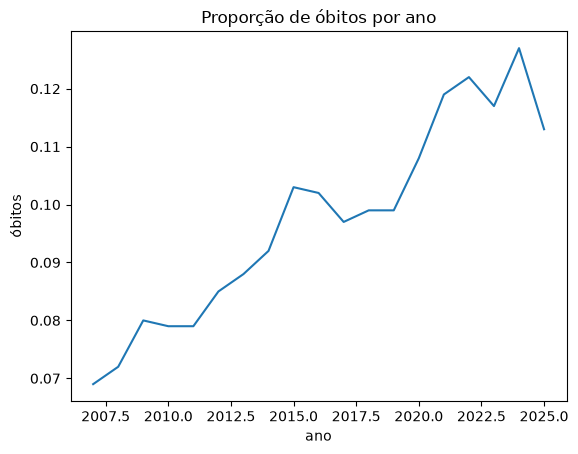

In [4]:
df.groupby('ano')['obito'].mean().round(3).plot(title='Proporção de óbitos por ano', ylabel='óbitos');

A proporção de óbitos **muda ao longo do tempo**. Se treinarmos com anos antigos e testarmos em anos recentes, o modelo enfrentará uma distribuição diferente da que aprendeu. É o que acontece no mundo real.

## 2. "Ignorado" também é informação

In [5]:
(df.select_dtypes(exclude='number') == 'Ignorado').mean().sort_values(ascending=False).round(3).head(8)

coinfeccao_hiv            0.213
quadro_infeccioso         0.074
raca_cor                  0.069
fenomenos_hemorragicos    0.059
ictericia                 0.057
edema                     0.052
hepatomegalia             0.045
palidez                   0.040
dtype: float64

In [6]:
df.groupby('coinfeccao_hiv')['obito'].agg(['mean', 'size']).round(3)

,mean,size
coinfeccao_hiv,,
Ignorado,0.096,9591
Não,0.089,30878
Sim,0.111,4572


Note que o grupo "Ignorado" pode ter um risco diferente de "Sim" e de "Não". Apagar essas linhas ou trocar por "Não" muda o resultado. Aqui mantemos "Ignorado" como uma categoria própria.

## 3. Separação temporal: treino até 2019, teste de 2020 em diante

In [7]:
y = df.pop('obito')
X = df
treino = X['ano'] <= 2019
X_tr, X_te, y_tr, y_te = X[treino], X[~treino], y[treino], y[~treino]
print(f"treino: {len(X_tr)} casos ({y_tr.mean():.1%} óbitos)")
print(f"teste:  {len(X_te)} casos ({y_te.mean():.1%} óbitos)")

treino: 36991 casos (8.8% óbitos)
teste:  8050 casos (11.7% óbitos)


## 4. Modelos

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier

categoricas = list(X.select_dtypes(exclude='number').columns)
numericas = ['idade']  # 'ano' fica de fora de propósito: veja a pergunta 3 no final

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas),
    ('num', StandardScaler(), numericas),
])

modelos = {
    'Sempre "não morreu"': DummyClassifier(strategy='most_frequent'),
    'Regressão logística': make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Gradient boosting': make_pipeline(pre, HistGradientBoostingClassifier(class_weight='balanced', random_state=0)),
}

In [9]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
                             average_precision_score, recall_score, precision_score)

linhas = []
for nome, modelo in modelos.items():
    modelo.fit(X_tr, y_tr)
    prob = modelo.predict_proba(X_te)[:, 1]
    pred = modelo.predict(X_te)
    linhas.append({
        'modelo': nome,
        'acurácia': accuracy_score(y_te, pred),
        'acurácia balanceada': balanced_accuracy_score(y_te, pred),
        'AUC-ROC': roc_auc_score(y_te, prob),
        'AUC-PR': average_precision_score(y_te, prob),
        'recall (óbitos detectados)': recall_score(y_te, pred),
        'precisão': precision_score(y_te, pred, zero_division=0),
    })
resultados = pd.DataFrame(linhas).set_index('modelo').round(3)
resultados

,acurácia,acurácia balanceada,AUC-ROC,AUC-PR,recall (óbitos detectados),precisão
modelo,,,,,,
"Sempre ""não morreu""",0.883,0.500,0.500,0.117,0.000,0.000
Regressão logística,0.614,0.665,0.737,0.300,0.732,0.195
Gradient boosting,0.646,0.676,0.752,0.317,0.715,0.208


### O que observar

- O modelo que **sempre diz "não morreu"** tem a maior acurácia e **não detecta nenhum óbito**. Acurácia sozinha não serve aqui.
- A **AUC-PR** de referência é a prevalência de óbitos no teste. Compare cada modelo com esse valor, não com zero.
- Com `class_weight='balanced'`, os modelos detectam a maioria dos óbitos, ao custo de muitos falsos alarmes (precisão baixa). Em saúde, o equilíbrio entre os dois depende do uso.

## 5. O que o modelo aprendeu?

In [10]:
from sklearn.inspection import permutation_importance

modelo = modelos['Gradient boosting']
imp = permutation_importance(modelo, X_te, y_te, scoring='average_precision', n_repeats=5, random_state=0)
pd.Series(imp.importances_mean, index=X_te.columns).sort_values(ascending=False).head(10).round(4)

idade                     0.1187
fenomenos_hemorragicos    0.0512
ictericia                 0.0237
edema                     0.0214
quadro_infeccioso         0.0076
emagrecimento             0.0044
exame_parasitologico      0.0035
raca_cor                  0.0022
tipo_entrada              0.0015
hepatomegalia             0.0015
dtype: float64

## Perguntas para a turma

1. **Acurácia.** Por que o modelo "sempre não morreu" tem 88% de acurácia? Que métrica você usaria para apresentar o resultado a um gestor de saúde?
2. **Limiar.** Mude o limiar de decisão (`prob > 0.3`, `prob > 0.7`). Como recall e precisão mudam? Em que situação clínica você preferiria cada um?
3. **Vazamento e tempo.** Inclua `ano` como variável numérica. O desempenho no teste melhora ou piora? Por quê?
4. **Ignorado.** Remova as linhas com "Ignorado" em `coinfeccao_hiv`. Quantos casos você perde? O modelo muda?
5. **Equidade.** Calcule o recall separadamente por `regiao` e por `raca_cor`. O modelo erra mais para algum grupo?
6. **Causalidade.** A importância de uma variável significa que ela *causa* óbito? Dê um exemplo em que isso seria uma interpretação errada.